In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
# Load Diabetes dataset

url = "diabetes - diabetes.csv"

df = pd.read_csv(url)

print(df.head())
print("\nDataset Shape:", df.shape)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Shape: (768, 9)


In [3]:
# Separate input features and target

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Features:")
print(X.columns)

print("\nTarget Classes:")
print(y.unique())

Features:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='str')

Target Classes:
[1 0]


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (614, 8)
Testing Data: (154, 8)


In [11]:
# Standardize input features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [12]:
# Create and train Linear SVM model
linear_svm = SVC(kernel="linear")

linear_svm.fit(X_train, y_train)

# Predict output
y_pred_linear = linear_svm.predict(X_test)

In [13]:
# Create and train RBF SVM model
rbf_svm = SVC(kernel="rbf")

rbf_svm.fit(X_train, y_train)

# Predict output
y_pred_rbf = rbf_svm.predict(X_test)

In [14]:
# Display Linear SVM performance
print("Linear SVM Performance")
print("----------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_linear))
print("Precision:", precision_score(y_test, y_pred_linear))
print("Recall   :", recall_score(y_test, y_pred_linear))
print("F1-score :", f1_score(y_test, y_pred_linear))

Linear SVM Performance
----------------------
Accuracy : 0.7207792207792207
Precision: 0.6222222222222222
Recall   : 0.5185185185185185
F1-score : 0.5656565656565656


In [15]:
# Display RBF SVM performance
print("\nRBF SVM Performance")
print("-------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_rbf))
print("Precision:", precision_score(y_test, y_pred_rbf))
print("Recall   :", recall_score(y_test, y_pred_rbf))
print("F1-score :", f1_score(y_test, y_pred_rbf))


RBF SVM Performance
-------------------
Accuracy : 0.7532467532467533
Precision: 0.66
Recall   : 0.6111111111111112
F1-score : 0.6346153846153846


In [16]:
# Compare performance of both models
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],

    "Linear SVM": [
        accuracy_score(y_test, y_pred_linear),
        precision_score(y_test, y_pred_linear),
        recall_score(y_test, y_pred_linear),
        f1_score(y_test, y_pred_linear)
    ],

    "RBF SVM": [
        accuracy_score(y_test, y_pred_rbf),
        precision_score(y_test, y_pred_rbf),
        recall_score(y_test, y_pred_rbf),
        f1_score(y_test, y_pred_rbf)
    ]
})

print(results)

      Metric  Linear SVM   RBF SVM
0   Accuracy    0.720779  0.753247
1  Precision    0.622222  0.660000
2     Recall    0.518519  0.611111
3   F1-score    0.565657  0.634615


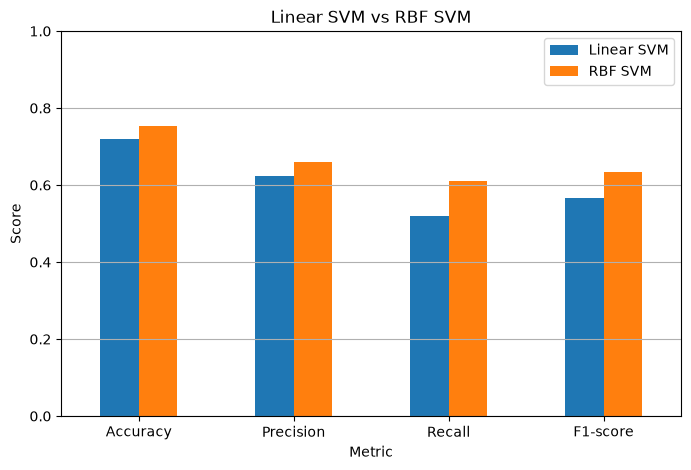

In [17]:
# Plot comparison graph
results.set_index("Metric").plot(kind="bar", figsize=(8, 5))

plt.title("Linear SVM vs RBF SVM")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

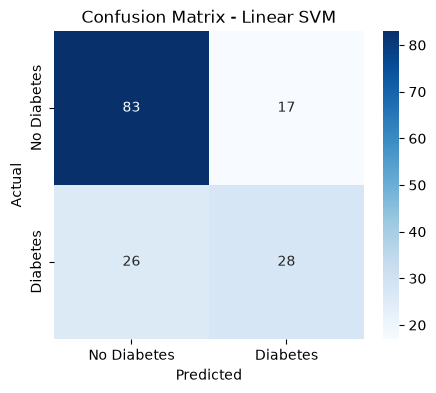

In [18]:
# Calculate confusion matrix
cm_linear = confusion_matrix(y_test, y_pred_linear)

# Display confusion matrix
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_linear,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Linear SVM")
plt.show()

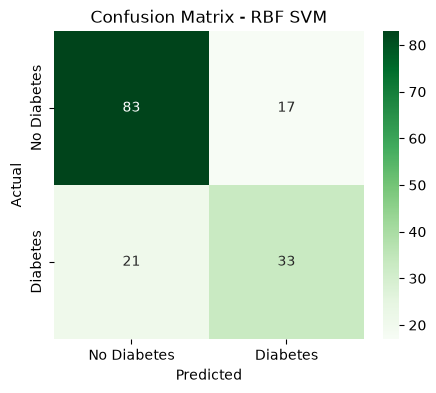

In [19]:
# Calculate confusion matrix
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

# Display confusion matrix
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_rbf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - RBF SVM")
plt.show()

In [20]:
# Display classification report for Linear SVM
print("Linear SVM Classification Report")
print("--------------------------------")
print(classification_report(y_test, y_pred_linear))

# Display classification report for RBF SVM
print("\nRBF SVM Classification Report")
print("-----------------------------")
print(classification_report(y_test, y_pred_rbf))

Linear SVM Classification Report
--------------------------------
              precision    recall  f1-score   support

           0       0.76      0.83      0.79       100
           1       0.62      0.52      0.57        54

    accuracy                           0.72       154
   macro avg       0.69      0.67      0.68       154
weighted avg       0.71      0.72      0.71       154


RBF SVM Classification Report
-----------------------------
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154

